# Chapter 17: Scopes

## Gloval scope

- Global names are variables assigned at the top level of the enclosing module file.
- Global names must be declared only if they are assigned within a function.
- Global names may be referenced within a function without being declared.

In [ ]:
x = 88 		# Global X

def func():
	x = 99 	# Local X: hides global, but we want this here

func()
print(x) #	 Prints 88: unchanged

88


In [ ]:
x = 88 			# Global X

def func():
	global x
	x = 99 		# Global X: outside def

func()
print("x =", x) # Prints 99

x = 99


## Regla LEGB 

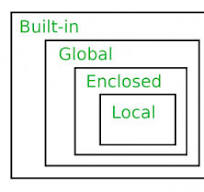

In [ ]:
# Global names may be referenced within a function without being declared.

y, z = 1, 2         # Global variables in module

def all_global():
	global x        # Declare globals assigned
	x = y + z       # No need to declare y, z: LEGB rule
                    # x existe ahora en el ambito global con valor 3

all_global()
print('x = %d, y = %d, z = %d' % (x, y, z))

x = 3, y = 1, z = 2


## Scopes anidadas

In [ ]:
x = 99                      # Global scope name: not used

def f1():
    x = 88
    def f2():               # Enclosing def local
        print("x local = ", x)    # Reference made in nested def
    f2()                    # f2 is a temporary function that lives only during the execution                               of (and is visible only to code in) the enclosing f1

f1()                        # Prints 88: enclosing def local
print("x global = ", x)     # salida: X = 88; X sigue valiendo 99

# f2()  NameError: name 'f2' is not defined  No se puede invocar a f2() desde el modulo principal

x local =  88
x global =  99


## Factory Functions: Closures


Un *closure* o una función de fábrica; el primero describe una técnica de programación funcional, mientras que el segundo designa un patrón de diseño. El objeto función en cuestión conserva valores de ámbitos envolventes, independientemente de si dichos ámbitos aún permanecen en la memoria.

In [ ]:
def f1():
	x = 88                 # enclosing scope
	def f2():
		print("x =", x)    # Remembers x in enclosing def scope
	return f2 	           # Return f2 but don't call it => f1() devuelve el objeto funcion con                              nombre (referencia) f2

action = f1()       # Make, return function => action es ahora una función: action = f2
action() 			# Call it now: prints 88  == f2()

# Functions are objects in Python like everything else, and can be passed back as return values from other functions. 
# Most importantly, f2 remembers the enclosing scope’s x in f1 , even though f1 is no longer active.

x = 88


In [ ]:
def maker(n):
	def action(x):		# Make and return action
		return x ** n 	# action retains n from enclosing scope
	return action

f = maker(2)            # Pass 2 to argument n -> return x ** 2
f(3)                    # Pass 3 to x, n remembers "2" -> return 3 ** 2

f(4)		            # return 4 ** 2

16